# Finger-count CNN training

Trains a small CNN from scratch on `data/<session>/<class>/*.png` (class 0 = fist / empty box, 1-5 = fingers).
Run top to bottom from the `laptop/` folder.

## 1. Settings

In [1]:
from pathlib import Path
import random

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset

DATA_DIR = Path("data")
IMG = 64          # images are resized to IMG x IMG on load (saved at 128)
TEST_FRAC = 0.2   # last 20% of each session/class folder -> test
EPOCHS = 50
BATCH = 64
LR = 1e-3
SEED = 0
NUM_CLASSES = 6

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cpu


/home/daniel-choate/miniconda3/envs/py312/lib/python3.12/site-packages/torch/cuda/__init__.py:129: UserWarning: CUDA initialization: CUDA unknown error - this may be due to an incorrectly set up environment, e.g. changing env variable CUDA_VISIBLE_DEVICES after program start. Setting the available devices to be zero. (Triggered internally at /pytorch/c10/cuda/CUDAFunctions.cpp:109.)
  return torch._C._cuda_getDeviceCount() > 0


## 2. Load data and split
Images are numbered in recording order. In every session/class folder the first 80% go to train and the
last 20% to test, so near-identical neighboring frames don't land on both sides.

In [2]:
def load_split():
    Xtr, ytr, Xte, yte = [], [], [], []
    for session in sorted(p for p in DATA_DIR.iterdir() if p.is_dir()):
        for c in range(NUM_CLASSES):
            files = sorted((session / str(c)).glob("*.png"))
            cut = int(len(files) * (1 - TEST_FRAC))
            for i, f in enumerate(files):
                img = cv2.imread(str(f), cv2.IMREAD_GRAYSCALE)
                img = cv2.resize(img, (IMG, IMG), interpolation=cv2.INTER_AREA)
                (Xtr if i < cut else Xte).append(img)
                (ytr if i < cut else yte).append(c)
    return np.array(Xtr), np.array(ytr), np.array(Xte), np.array(yte)


Xtr, ytr, Xte, yte = load_split()
print("train:", Xtr.shape, np.bincount(ytr, minlength=NUM_CLASSES))
print("test: ", Xte.shape, np.bincount(yte, minlength=NUM_CLASSES))

train: (3875, 64, 64) [826 605 609 609 616 610]
test:  (976, 64, 64) [208 153 153 153 155 154]


## 3. Augmentation and Dataset
Training images only: random flip, rotation (±15°), zoom (0.9-1.1), shift (±10%), brightness/contrast.
Pixels are scaled to 0-1 and given a channel dimension: `(1, IMG, IMG)`.

In [3]:
def augment(img):
    if random.random() < 0.5:
        img = cv2.flip(img, 1)
    angle = random.uniform(-15, 15)
    scale = random.uniform(0.9, 1.1)
    M = cv2.getRotationMatrix2D((IMG / 2, IMG / 2), angle, scale)
    M[:, 2] += np.random.uniform(-0.1, 0.1, 2) * IMG
    img = cv2.warpAffine(img, M, (IMG, IMG), borderMode=cv2.BORDER_REFLECT)
    contrast = random.uniform(0.8, 1.2)
    brightness = random.uniform(-20, 20)
    return np.clip(img.astype(np.float32) * contrast + brightness, 0, 255)


class FingerData(Dataset):
    def __init__(self, X, y, train):
        self.X, self.y, self.train = X, y, train

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        img = augment(self.X[i]) if self.train else self.X[i].astype(np.float32)
        x = torch.from_numpy(img / 255.0).float().unsqueeze(0)
        return x, int(self.y[i])


train_dl = DataLoader(FingerData(Xtr, ytr, True), batch_size=BATCH, shuffle=True)
test_dl = DataLoader(FingerData(Xte, yte, False), batch_size=BATCH)

Quick look: top row = original training images, bottom row = the same images augmented.

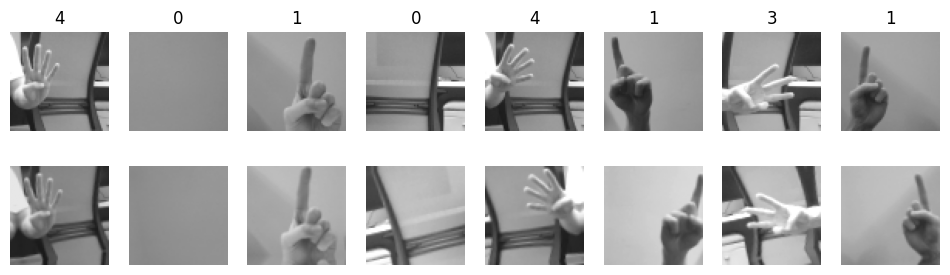

In [4]:
idx = np.random.choice(len(Xtr), 8, replace=False)
fig, ax = plt.subplots(2, 8, figsize=(12, 3.2))
for j, i in enumerate(idx):
    ax[0, j].imshow(Xtr[i], cmap="gray", vmin=0, vmax=255)
    ax[0, j].set_title(ytr[i])
    ax[1, j].imshow(augment(Xtr[i]), cmap="gray", vmin=0, vmax=255)
for a in ax.flat:
    a.axis("off")
plt.show()

## 4. Model
Each block: 3x3 conv -> batch norm -> ReLU -> 2x2 max-pool (halves width/height).

| Layer | Output | Params |
|---|---|---|
| Block 1: 1 → 16 | 16 × 32 × 32 | 192 |
| Block 2: 16 → 32 | 32 × 16 × 16 | 4.7k |
| Block 3: 32 → 64 | 64 × 8 × 8 | 18.6k |
| Block 4: 64 → 128 | 128 × 4 × 4 | 74.1k |
| Global avg pool | 128 | 0 |
| Dropout 0.3 | 128 | 0 |
| Linear | 6 | 774 |

In [5]:
def block(c_in, c_out):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, kernel_size=3, padding=1),
        nn.BatchNorm2d(c_out),
        nn.ReLU(),
        nn.MaxPool2d(2),
    )


class FingerNet(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES):
        super().__init__()
        self.features = nn.Sequential(block(1, 16), block(16, 32), block(32, 64), block(64, 128))
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.features(x)          # (B, 128, 4, 4)
        x = self.pool(x).flatten(1)   # (B, 128)
        return self.fc(self.dropout(x))  # (B, 6) class scores


model = FingerNet().to(device)
print(model)
print("params:", sum(p.numel() for p in model.parameters()))

FingerNet(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (3): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3),

## 5. Train
Cross-entropy loss, Adam. Keeps the epoch with the best test accuracy in `model.pt`.

In [ ]:
loss_fn = nn.CrossEntropyLoss()
opt = torch.optim.Adam(model.parameters(), lr=LR)


def run_epoch(dl, train):
    model.train(train)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in dl:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = loss_fn(out, y)
            if train:
                opt.zero_grad()
                loss.backward()
                opt.step()
            total_loss += loss.item() * len(y)
            correct += (out.argmax(1) == y).sum().item()
            n += len(y)
    return total_loss / n, correct / n


hist = {"train_loss": [], "test_loss": [], "train_acc": [], "test_acc": []}
best_acc = 0.0
for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = run_epoch(train_dl, True)
    te_loss, te_acc = run_epoch(test_dl, False)
    for k, v in zip(hist, (tr_loss, te_loss, tr_acc, te_acc)):
        hist[k].append(v)
    flag = ""
    if te_acc > best_acc:
        best_acc = te_acc
        torch.save({"state_dict": model.state_dict(), "img": IMG}, "model.pt")
        flag = "  * saved"
    print(f"epoch {epoch:2d}  train {tr_loss:.3f} / {tr_acc:.3f}   test {te_loss:.3f} / {te_acc:.3f}{flag}")
print("best test acc:", best_acc)

## 6. Loss and accuracy curves
Saved to `loss.png`.

In [ ]:
ep = range(1, len(hist["train_loss"]) + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ep, hist["train_loss"], label="train")
ax[0].plot(ep, hist["test_loss"], label="test")
ax[0].set(title="Loss", xlabel="epoch", ylabel="cross-entropy")
ax[1].plot(ep, hist["train_acc"], label="train")
ax[1].plot(ep, hist["test_acc"], label="test")
ax[1].set(title="Accuracy", xlabel="epoch", ylabel="accuracy")
for a in ax:
    a.legend(); a.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("loss.png", dpi=120)
plt.show()

## 7. Confusion matrix (best model, test set)
Rows = true class, columns = predicted class.

In [ ]:
model.load_state_dict(torch.load("model.pt")["state_dict"])
model.eval()
preds = []
with torch.no_grad():
    for x, _ in test_dl:
        preds.append(model(x.to(device)).argmax(1).cpu().numpy())
preds = np.concatenate(preds)

cm = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=int)
for t, p in zip(yte, preds):
    cm[t, p] += 1
print(cm)

plt.figure(figsize=(5, 4.5))
plt.imshow(cm, cmap="Blues")
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        plt.text(j, i, cm[i, j], ha="center", va="center",
                 color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.xticks(range(NUM_CLASSES)); plt.yticks(range(NUM_CLASSES))
plt.xlabel("predicted"); plt.ylabel("true"); plt.title("Test confusion matrix")
plt.colorbar(); plt.tight_layout(); plt.show()

Misclassified test images (title = true → predicted).

In [ ]:
wrong = np.where(preds != yte)[0]
print(len(wrong), "wrong of", len(yte))
show = wrong[:16]
if len(show):
    fig, ax = plt.subplots(2, 8, figsize=(12, 3.4))
    for a in ax.flat:
        a.axis("off")
    for a, i in zip(ax.flat, show):
        a.imshow(Xte[i], cmap="gray", vmin=0, vmax=255)
        a.set_title(f"{yte[i]} → {preds[i]}")
    plt.show()

## 8. Export to ONNX for the board
Writes `../python/model.onnx` so it deploys with the app. The board runs it with OpenCV's `cv2.dnn` (no torch needed).
Then checks that `cv2.dnn` gives the same scores as PyTorch on a few test images.

In [7]:
model = FingerNet()
model.load_state_dict(torch.load("model.pt", map_location="cpu")["state_dict"])
model.eval()  # turns off dropout, batch norm uses its saved stats

ONNX_PATH = Path("../python/model.onnx")
dummy = torch.zeros(1, 1, IMG, IMG)
torch.onnx.export(model, dummy, str(ONNX_PATH), input_names=["image"], output_names=["scores"],
                  opset_version=13, dynamo=False)
print("saved", ONNX_PATH, f"({ONNX_PATH.stat().st_size / 1024:.0f} KB)")

# Check: same test images through PyTorch and cv2.dnn
net = cv2.dnn.readNetFromONNX(str(ONNX_PATH))
idx = np.random.choice(len(Xte), 20, replace=False)
max_diff, agree = 0.0, 0
for i in idx:
    x = (Xte[i].astype(np.float32) / 255.0)[None, None]  # (1, 1, IMG, IMG)
    with torch.no_grad():
        ref = model(torch.from_numpy(x)).numpy()
    net.setInput(x)
    out = net.forward()
    max_diff = max(max_diff, np.abs(ref - out).max())
    agree += ref.argmax() == out.argmax()
print(f"max score difference: {max_diff:.2e}   same prediction: {agree}/{len(idx)}")

saved ../python/model.onnx (386 KB)
max score difference: 2.96e-05   same prediction: 20/20
